EJERCICIO R2 (REPLICAR): CLASIFICACIÓN F1

--- PASO 1: MODELO ---
max z = 10*x1 + 7*x2
s.a.
  2*x1 + 1*x2 <= 14  (túnel de viento)
  1*x1 + 3*x2 <= 18  (horas de CFD)
  1*x1 + 1*x2 <= 10  (presupuesto)
  x1, x2 >= 0

--- PASO 2: FORMA ESTÁNDAR ---
  2*x1 + 1*x2 + s1 = 14
  1*x1 + 3*x2 + s2 = 18
  1*x1 + 1*x2 + s3 = 10
  z - 10*x1 - 7*x2 = 0

--- PASO 3: SOLUCIÓN CON SCIPY ---
  x1 = 4.8000
  x2 = 4.4000
  z  = 78.8000

--- PASO 4: VERIFICACIÓN MANUAL ---
  Túnel: 2(4.8) + 1(4.4) = 14.00 <= 14
  CFD:   1(4.8) + 3(4.4) = 18.00 <= 18
  Presupuesto: 1(4.8) + 1(4.4) = 9.20 <= 10
  Puntos: 10(4.8) + 7(4.4) = 78.80

--- PASO 5: GRÁFICO ---


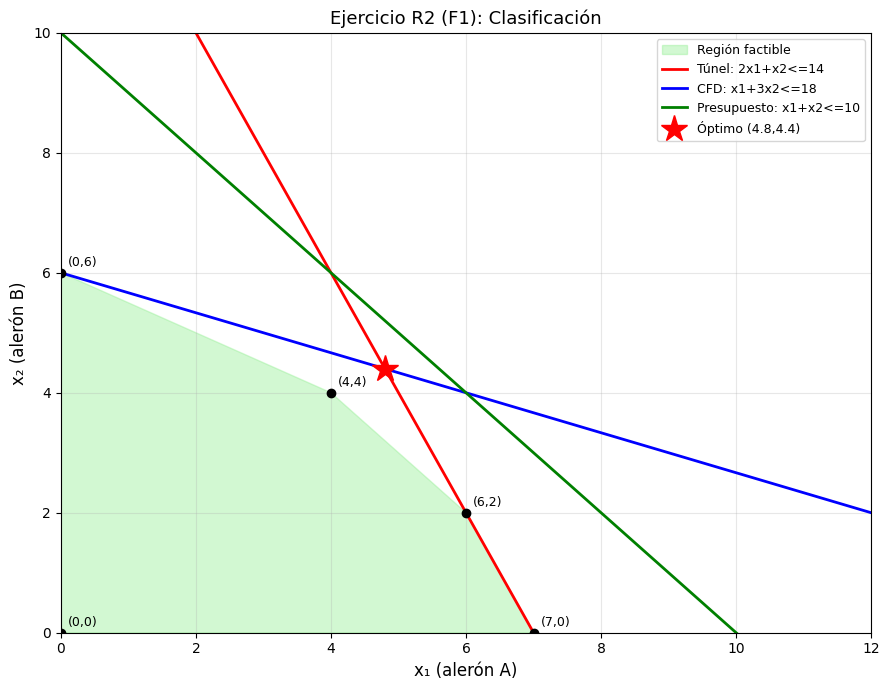


--- PASO 6: RESPUESTA ESPERADA ---
  x1 = 6, x2 = 2, z = 74
  Verificación: 2(6)+2=14 <= 14, 6+3(2)=12 <= 18, 6+2=8 <= 10

--- PASO 7: ANÁLISIS ---
1. Conviene usar 6 unidades del alerón A y 2 del alerón B.
2. El túnel de viento se agota (cuello de botella).
3. CFD y presupuesto tienen holgura.
4. El precio sombra del túnel es 6 puntos por hora extra.
5. El alerón A es más eficiente (10 puntos vs 7).


In [1]:
# =====================================================================
# EJERCICIO R2 (REPLICAR): Clasificación F1
# =====================================================================
# PROBLEMA:
#   Dos configuraciones de alerón: A (x1) da 10 puntos, B (x2) da 7.
#   Restricciones:
#     2x1 + x2 <= 14  (túnel de viento)
#     x1 + 3x2 <= 18  (horas de CFD)
#     x1 + x2  <= 10  (presupuesto)
#
# OBJETIVO: maximizar puntos.
# =====================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

print("="*70)
print("EJERCICIO R2 (REPLICAR): CLASIFICACIÓN F1")
print("="*70)

# ---------------------------------------------------------------------
# PASO 1: MODELO
# ---------------------------------------------------------------------
print("\n--- PASO 1: MODELO ---")
print("max z = 10*x1 + 7*x2")
print("s.a.")
print("  2*x1 + 1*x2 <= 14  (túnel de viento)")
print("  1*x1 + 3*x2 <= 18  (horas de CFD)")
print("  1*x1 + 1*x2 <= 10  (presupuesto)")
print("  x1, x2 >= 0")

# ---------------------------------------------------------------------
# PASO 2: FORMA ESTÁNDAR
# ---------------------------------------------------------------------
print("\n--- PASO 2: FORMA ESTÁNDAR ---")
print("  2*x1 + 1*x2 + s1 = 14")
print("  1*x1 + 3*x2 + s2 = 18")
print("  1*x1 + 1*x2 + s3 = 10")
print("  z - 10*x1 - 7*x2 = 0")

# ---------------------------------------------------------------------
# PASO 3: SOLUCIÓN CON LINPROG
# ---------------------------------------------------------------------
print("\n--- PASO 3: SOLUCIÓN CON SCIPY ---")
c = [-10, -7]
A_ub = [[2, 1], [1, 3], [1, 1]]
b_ub = [14, 18, 10]
bounds = [(0, None), (0, None)]

res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs')

print(f"  x1 = {res.x[0]:.4f}")
print(f"  x2 = {res.x[1]:.4f}")
print(f"  z  = {-res.fun:.4f}")

# ---------------------------------------------------------------------
# PASO 4: VERIFICACIÓN MANUAL
# ---------------------------------------------------------------------
print("\n--- PASO 4: VERIFICACIÓN MANUAL ---")
print(f"  Túnel: 2({res.x[0]:.1f}) + 1({res.x[1]:.1f}) = "
      f"{2*res.x[0]+res.x[1]:.2f} <= 14")
print(f"  CFD:   1({res.x[0]:.1f}) + 3({res.x[1]:.1f}) = "
      f"{res.x[0]+3*res.x[1]:.2f} <= 18")
print(f"  Presupuesto: 1({res.x[0]:.1f}) + 1({res.x[1]:.1f}) = "
      f"{res.x[0]+res.x[1]:.2f} <= 10")
print(f"  Puntos: 10({res.x[0]:.1f}) + 7({res.x[1]:.1f}) = "
      f"{-res.fun:.2f}")

# ---------------------------------------------------------------------
# PASO 5: GRÁFICO
# ---------------------------------------------------------------------
print("\n--- PASO 5: GRÁFICO ---")

fig, ax = plt.subplots(figsize=(9, 7))

vertices = [(0, 0), (7, 0), (6, 2), (4, 4), (0, 6)]
verts = np.array(vertices)
ax.fill(verts[:, 0], verts[:, 1], color='lightgreen', alpha=0.4,
        label='Región factible')

x = np.linspace(0, 12, 400)
ax.plot(x, 14 - 2*x, 'r-', linewidth=2,
        label='Túnel: 2x1+x2<=14')
ax.plot(x, (18 - x)/3, 'b-', linewidth=2,
        label='CFD: x1+3x2<=18')
ax.plot(x, 10 - x, 'g-', linewidth=2,
        label='Presupuesto: x1+x2<=10')

for v in vertices:
    ax.plot(v[0], v[1], 'ko', markersize=6)
    ax.annotate(f"({v[0]},{v[1]})", v, textcoords="offset points",
                xytext=(5, 5), fontsize=9)

ax.plot(res.x[0], res.x[1], 'r*', markersize=20,
        label=f'Óptimo ({res.x[0]:.1f},{res.x[1]:.1f})')

ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.set_xlabel('x₁ (alerón A)', fontsize=12)
ax.set_ylabel('x₂ (alerón B)', fontsize=12)
ax.set_title('Ejercicio R2 (F1): Clasificación', fontsize=13)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc='best')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# PASO 6: RESPUESTA ESPERADA Y ANÁLISIS
# ---------------------------------------------------------------------
print("\n--- PASO 6: RESPUESTA ESPERADA ---")
print("  x1 = 6, x2 = 2, z = 74")
print("  Verificación: 2(6)+2=14 <= 14, 6+3(2)=12 <= 18, 6+2=8 <= 10")
print("\n--- PASO 7: ANÁLISIS ---")
print("1. Conviene usar 6 unidades del alerón A y 2 del alerón B.")
print("2. El túnel de viento se agota (cuello de botella).")
print("3. CFD y presupuesto tienen holgura.")
print("4. El precio sombra del túnel es 6 puntos por hora extra.")
print("5. El alerón A es más eficiente (10 puntos vs 7).")
print("="*70)